# IRWA Final Project — Part 2: Indexing and Evaluation

This notebook (1) builds an inverted index over the corpus processed in Part 1, (2) answers
conjunctive (AND) queries ranked by TF-IDF and (3) evaluates the results.
The indexing and ranking functions live in `myapp/search/algorithms.py` and the metrics in
`myapp/search/evaluation.py`, so Parts 3–4 reuse them. Queries go through the same
`preprocess_text` from `myapp/core/preprocessing.py` as the documents.

**Run from the repository root or from this folder.** Required files:
`data/processed_corpus.pkl` (output of Part 1), `data/validation_labels.csv` and
`project_progress/part_2/test_queries_to_label.csv`.

In [1]:
import sys, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

# Locate the repository root (the folder that contains `myapp/`) so the notebook works
# whether it is launched from the repo root or from project_progress/part_2.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "myapp").is_dir())
sys.path.insert(0, str(ROOT))

for resource in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(resource, quiet=True)

from myapp.core.preprocessing import load_raw_corpus, preprocess_corpus, preprocess_text
from myapp.search.algorithms import create_index, conjunctive_search, search_in_corpus
from myapp.search.evaluation import (
    get_labels_and_scores, precision_at_k, recall_at_k, f1_at_k, avg_precision_at_k,
    rr_at_k, ndcg_at_k, map_at_k, mrr_at_k,
)

DATA = ROOT / "data"
PART2 = ROOT / "project_progress" / "part_2"
FIG = PART2 / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
warnings.filterwarnings("ignore")

def savefig(name):
    """Save the current figure into project_progress/part_2/figures for the report."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

## 1. Loading the processed corpus

In [2]:
corpus_path = DATA / "processed_corpus.pkl"
if corpus_path.exists():
    corpus = pd.read_pickle(corpus_path)
else:
    # Part 1 output missing: rebuild it with the same pipeline.
    corpus = preprocess_corpus(load_raw_corpus(DATA / "fashion_products_dataset.json"))
    corpus.to_pickle(corpus_path)
print(f"{len(corpus):,} products")
corpus[["pid", "title", "title_tokens", "all_tokens"]].head(3)

28,080 products


,pid,title,title_tokens,all_tokens
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]","[solid, women, multicolor, track, pant, yorker, trackpant, made, rich, comb,..."
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,"[solid, men, blue, track, pant]","[solid, men, blue, track, pant, yorker, trackpant, made, rich, comb, cotton,..."
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant]","[solid, men, multicolor, track, pant, yorker, trackpant, made, rich, comb, c..."


## 2. Inverted index

Following the Part 1 decision, the index is built on `all_tokens` (title + description +
retained `product_details` values + brand). The per-field token columns are kept for field
weighting in Part 3. `create_index` returns three structures:

```
index[term] = [pid_1, pid_2, ...]          # postings list (the lab vocabulary structure)
tf[term]    = {pid: count / ||d||}         # tf normalised by the length of the document vector
idf[term]   = log(N / df)
```

In [3]:
%%time
index, tf, idf = create_index(corpus)

CPU times: user 185 ms, sys: 7.82 ms, total: 193 ms
Wall time: 192 ms


In [4]:
N = len(corpus)
postings_len = pd.Series({t: len(p) for t, p in index.items()})
doc_len = corpus.all_tokens.str.len()
print(f"Vocabulary size: {len(index):,} terms over {N:,} documents")
print(f"Total postings: {postings_len.sum():,}")
print(f"Postings length: median {postings_len.median():.0f}, mean {postings_len.mean():.1f}, max {postings_len.max():,}")
print("\nExample, first postings of 'sweatshirt':", index["sweatshirt"][:5])
postings_len.describe().round(1)

Vocabulary size: 5,710 terms over 28,080 documents
Total postings: 795,585
Postings length: median 6, mean 139.3, max 20,784

Example, first postings of 'sweatshirt': ['SWSFYD33P2XCBWFG', 'SWSFYD3KMGTBZEJZ', 'SWSFYD38Y2MAT9FQ', 'SWSFVEV2YFEJKUCK', 'SWSFVEV2BWZJDJ46']


count     5710.0
mean       139.3
std        844.6
min          1.0
25%          2.0
50%          6.0
75%         39.0
max      20784.0
dtype: float64

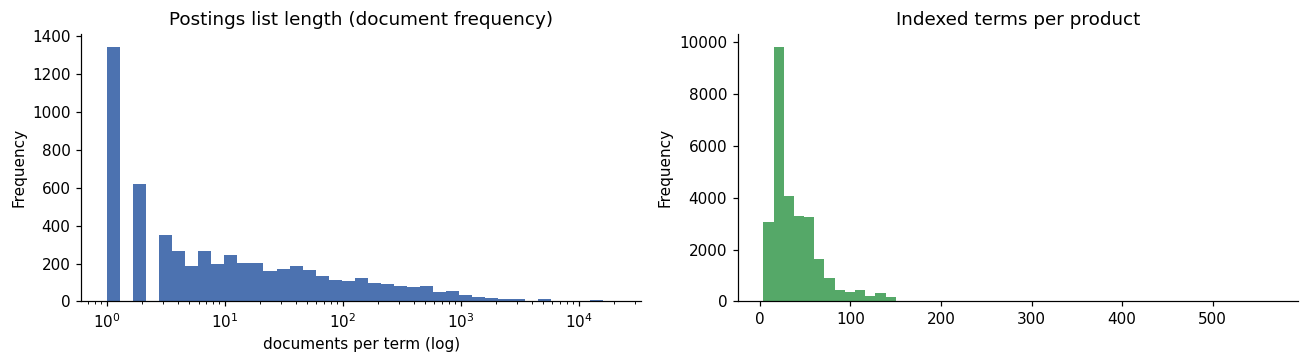

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
postings_len.plot.hist(bins=np.logspace(0, np.log10(postings_len.max()), 40), ax=axes[0], color="#4C72B0", logx=True,
                       title="Postings list length (document frequency)")
axes[0].set_xlabel("documents per term (log)")
doc_len.plot.hist(bins=50, ax=axes[1], color="#55A868", title="Indexed terms per product")
savefig("index_postings")
plt.show()

### Conjunctive (AND) queries

A product matches only if it contains **every** query term: `conjunctive_search` intersects
the postings lists of the query terms. If one term is not in the vocabulary the result is empty.

In [6]:
VALIDATION_QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}

for qid, q in VALIDATION_QUERIES.items():
    terms = preprocess_text(q)
    dfs = {t: len(index.get(t, [])) for t in terms}
    print(f"Query {qid}: {q}\n  terms {dfs}\n  -> {len(conjunctive_search(terms, index)):,} matching products\n")

Query 1: women full sleeve sweatshirt cotton
  terms {'women': 13702, 'full': 7174, 'sleev': 17911, 'sweatshirt': 1418, 'cotton': 19866}
  -> 479 matching products

Query 2: men slim jeans blue
  terms {'men': 13410, 'slim': 5666, 'jean': 2436, 'blue': 7104}
  -> 218 matching products



## 3. Test queries

To choose our queries we look at term popularity: document frequency (how many products contain
the term) and the TF-IDF mass of the term over the collection (sum of `tf * idf` over the
documents that contain it). Very frequent terms (gender, product type) form the base of a
query; attribute terms (fabric, colour, style) narrow it down.

In [7]:
popularity = pd.DataFrame({
    "df": postings_len,
    "idf": pd.Series(idf),
    "tfidf_mass": pd.Series({t: sum(tf[t].values()) * idf[t] for t in index}),
}).round(2)
pd.concat({
    "by document frequency": popularity.sort_values("df", ascending=False).head(25).reset_index(names="term"),
    "by TF-IDF mass": popularity.sort_values("tfidf_mass", ascending=False).head(25).reset_index(names="term"),
}, axis=1)

by document frequency                         by TF-IDF mass               \
                    term     df   idf tfidf_mass           term     df   idf   
0                   wear  20784  0.30    1054.25          print   9499  1.08   
1                 cotton  19866  0.35    1406.16         tshirt  13037  0.77   
2                western  19118  0.38    1002.06          round   9511  1.08   
3                  sleev  17911  0.45    1448.42          solid  12013  0.85   
4                   neck  14585  0.66    2477.28          shirt   4798  1.77   
5                  women  13702  0.72    2557.40            men  13410  0.74   
6                  blend  13593  0.73    1545.74          women  13702  0.72   
7                    men  13410  0.74    2578.09           neck  14585  0.66   
8                regular  13203  0.75    1687.26          black   6073  1.53   
9                 tshirt  13037  0.77    3032.58           slim   5666  1.60   
10                 solid  12013  0.85    2602.73           blue   7104  1.37   
11                   fit  10582  0.98    1684.20           polo   3040  2.22   
12                casual   9703  1.06    1669.95           full   7174  1.36   
13                 round   9511  1.08    2761.21        regular  13203  0.75   
14                 print   9499  1.08    3222.55            fit  10582  0.98   
15                  half   8548  1.19    1453.08         casual   9703  1.06   
16                  full   7174  1.36    1940.04          white   3587  2.06   
17               comfort   7143  1.37    1324.57          short   4950  1.74   
18                  blue   7104  1.37    2228.92     multicolor   4700  1.79   
19                 black   6073  1.53    2405.18           pack   4930  1.74   
20                  slim   5666  1.60    2265.37           grey   3008  2.23   
21                  pure   5514  1.63    1397.49          blend  13593  0.73   
22                design   5426  1.64    1388.33         fabric   5237  1.68   
23                fabric   5237  1.68    1453.60           half   8548  1.19   
24                  look   5126  1.70    1239.23          sleev  17911  0.45   

               
   tfidf_mass  
0     3222.55  
1     3032.58  
2     2761.21  
3     2602.73  
4     2602.63  
5     2578.09  
6     2557.40  
7     2477.28  
8     2405.18  
9     2265.37  
10    2228.92  
11    1981.48  
12    1940.04  
13    1687.26  
14    1684.20  
15    1669.95  
16    1650.95  
17    1590.69  
18    1590.53  
19    1571.40  
20    1568.19  
21    1545.74  
22    1453.60  
23    1453.08  
24    1448.42

Every test query combines a **gender**, a **product type** and one or two **attributes**,
which is how users usually search a fashion catalogue:

| id | query | structure |
|---|---|---|
| 1 | men cotton polo tshirt | gender + fabric + style + product |
| 2 | women cotton kurta | gender + fabric + product (ethnic wear) |
| 3 | men hooded sweatshirt | gender + style + product |
| 4 | men running shoes | gender + use + product (footwear) |
| 5 | women blue denim jacket | gender + colour + fabric + product |

In [8]:
test_labels = pd.read_csv(PART2 / "test_queries_to_label.csv")
TEST_QUERIES = test_labels.drop_duplicates("query_id").set_index("query_id")["query"].to_dict()

rows = []
for qid, q in TEST_QUERIES.items():
    terms = preprocess_text(q)
    rows.append({"query_id": qid, "query": q, "terms": terms,
                 "df per term": [len(index.get(t, [])) for t in terms],
                 "AND matches": len(conjunctive_search(terms, index))})
pd.DataFrame(rows).set_index("query_id")

,query,terms,df per term,AND matches
query_id,,,,
1,men cotton polo tshirt,"[men, cotton, polo, tshirt]","[13410, 19866, 3040, 13037]",1213
2,women cotton kurta,"[women, cotton, kurta]","[13702, 19866, 785]",358
3,men hooded sweatshirt,"[men, hood, sweatshirt]","[13410, 1031, 1418]",323
4,men running shoes,"[men, run, shoe]","[13410, 772, 526]",37
5,women blue denim jacket,"[women, blue, denim, jacket]","[13702, 7104, 1766, 1093]",27


## 4. TF-IDF ranking

`rank_documents` scores every product returned by the AND filter with the dot product of the
query and document TF-IDF vectors:

* document: $w_{t,d} = \dfrac{tf_{t,d}}{\lVert d \rVert} \cdot idf_t$ — tf normalised by the length of the document vector, so long descriptions do not win just for being long
* query: $w_{t,q} = \dfrac{tf_{t,q}}{\lVert q \rVert} \cdot idf_t$
* score: $\text{score}(q, d) = \sum_{t \in q} w_{t,q} \cdot w_{t,d}$

Ties are broken by `pid` so the ranking is reproducible.

In [9]:
pid_to_title = dict(zip(corpus.pid, corpus.title))

def search(query, top_k=20):
    """Run search_in_corpus and return a results table [rank, pid, score, title]."""
    res = pd.DataFrame(search_in_corpus(query, index, tf, idf, k=top_k), columns=["pid", "score"])
    res.insert(0, "rank", np.arange(1, len(res) + 1))
    res["title"] = res.pid.map(pid_to_title)
    return res.round({"score": 4})

for qid, q in VALIDATION_QUERIES.items():
    print(f"Query {qid}: {q}")
    display(search(q, top_k=10))

Query 1: women full sleeve sweatshirt cotton


,rank,pid,score,title
0,1,SWSFMTNHEM5SNHVZ,3.0082,Full Sleeve Solid Women Sweatshirt
1,2,SWSFMJGS8HVBPEH6,2.6051,Full Sleeve Solid Women Sweatshirt
2,3,SWSFMJGTGZMJXK5H,2.5861,Full Sleeve Solid Women Sweatshirt
3,4,SWSFMJGTQFMZGZQH,2.5861,Full Sleeve Solid Women Sweatshirt
4,5,SWSFMJGTVFW3NAXZ,2.5861,Full Sleeve Solid Women Sweatshirt
5,6,SWSFZVTNGM4HG8BC,2.5308,Full Sleeve Printed Women Sweatshirt
6,7,SWSFZVTTQCB4SJ7F,2.5308,Full Sleeve Solid Women Sweatshirt
7,8,SWSFNV7N26KC54MB,2.4529,Full Sleeve Solid Women Sweatshirt
8,9,SWSFWTND3EPMFCQD,2.3389,Full Sleeve Solid Women Sweatshirt
9,10,SWSFWTNDJFCF72WU,2.3272,Full Sleeve Solid Women Sweatshirt


Query 2: men slim jeans blue


,rank,pid,score,title
0,1,JEAF2QF6HNZHDXVX,2.2952,Slim Men Dark Blue Jeans
1,2,JEAFRAQXEKGUPNUN,2.2075,Slim Men Blue Jeans
2,3,JEAFJM2P2FQQJF3C,2.1543,Slim Men Dark Blue Jeans
3,4,JEAFSKYHDYZK5SHZ,2.1292,Slim Men Blue Jeans
4,5,JEAFSKYHRVZSABPR,2.1292,Slim Men Blue Jeans
5,6,JEAFSKYHTE76YWH7,2.1292,Slim Men Blue Jeans
6,7,JEAFTGSGTYKZGAEZ,2.0665,Slim Men Blue Jeans
7,8,JEAF8HYN5B9ZU6FP,2.0468,Slim Men Blue Jeans
8,9,JEAFV8WURBM7PGYT,2.0211,Slim Men Blue Jeans
9,10,JEAFVDRJZ5RWAFHB,2.0211,Slim Men Blue Jeans


## 5. Evaluation metrics

Implemented in `myapp/search/evaluation.py`, in the format used in the labs: for each query,
`y_true` holds the relevance label of every judged product and `y_score` the score our system
gives it. `top_k_labels` sorts the judged products by score and keeps the first *k*; products
with score 0 were not returned by the AND search, so they never count as retrieved.
*R* is the number of judged relevant products.

| metric | definition |
|---|---|
| P@K | $\frac{1}{K}\sum_{i=1}^{K} rel_i$ |
| R@K | $\frac{1}{R}\sum_{i=1}^{K} rel_i$ |
| AP@K | mean of $P@i$ over the relevant positions $i \le K$ |
| F1@K | $\frac{2 \cdot P@K \cdot R@K}{P@K + R@K}$ |
| MAP@K | mean of AP@K over the queries |
| MRR@K | mean over queries of $1 / \text{rank of the first relevant result}$ in the top K (0 if none) |
| NDCG@K | $DCG@K / IDCG@K$, with $DCG@K = \sum_{i=1}^{K} \frac{rel_i}{\log_2(i+1)}$ and IDCG the DCG of the ideal ranking |

Sanity check on a toy query with values computed by hand: six judged products, three relevant,
and the last one is not returned by the search (score 0).

In [10]:
y_true = np.array([1, 0, 1, 0, 0, 1])
y_score = np.array([6, 5, 4, 3, 2, 0])      # top-5 labels: 1 0 1 0 0
checks = {
    "P@5":    (precision_at_k(y_true, y_score, 5),     2 / 5),
    "R@5":    (recall_at_k(y_true, y_score, 5),        2 / 3),
    "F1@5":   (f1_at_k(y_true, y_score, 5),            2 * 0.4 * (2 / 3) / (0.4 + 2 / 3)),
    "AP@5":   (avg_precision_at_k(y_true, y_score, 5), (1 + 2 / 3) / 2),
    "RR@5":   (rr_at_k(y_true, y_score, 5),            1.0),
    "NDCG@5": (ndcg_at_k(y_true, y_score, 5),          (1 + 1 / 2) / (1 + 1 / math.log2(3) + 1 / 2)),
    "MAP@5":  (map_at_k([(y_true, y_score), (np.array([0, 1]), np.array([2, 1]))], 5), ((1 + 2 / 3) / 2 + 1 / 2) / 2),
    "MRR@5":  (mrr_at_k([(y_true, y_score), (np.array([0, 1]), np.array([2, 1]))], 5), (1 + 1 / 2) / 2),
}
for name, (got, expected) in checks.items():
    assert math.isclose(got, expected), name
pd.DataFrame(checks, index=["computed", "expected"]).T.round(3)

,computed,expected
P@5,0.400,0.400
R@5,0.667,0.667
F1@5,0.500,0.500
AP@5,0.833,0.833
RR@5,1.000,1.000
NDCG@5,0.704,0.704
MAP@5,0.667,0.667
MRR@5,0.750,0.750


In [11]:
K_VALUES = [5, 10, 20]

def metrics_table(runs, ks=K_VALUES):
    """
    All metrics for every query and cut-off.
    :param runs: {query_id: (y_true, y_score)}
    :return: one row per query plus a `mean` row (MAP@K in the AP columns, MRR@K in the RR columns)
    """
    table = pd.DataFrame({
        qid: {f"{name}@{k}": fn(y_true, y_score, k)
              for k in ks
              for name, fn in [("P", precision_at_k), ("R", recall_at_k), ("F1", f1_at_k),
                               ("AP", avg_precision_at_k), ("RR", rr_at_k), ("NDCG", ndcg_at_k)]}
        for qid, (y_true, y_score) in runs.items()
    }).T
    table.index.name = "query_id"
    table.loc["mean"] = table.mean()
    for k in ks:   # same values as the mean row, computed with the library functions
        assert math.isclose(table.loc["mean", f"AP@{k}"], map_at_k(list(runs.values()), k))
        assert math.isclose(table.loc["mean", f"RR@{k}"], mrr_at_k(list(runs.values()), k))
    return table.astype(float).round(3)

## 6. Evaluation on `validation_labels.csv`

* Each judged product gets the score of our full pipeline (AND filter + TF-IDF); judged products
  the AND search does not return get score 0 and are never retrieved.
* *R* = number of products labelled 1 for the query in the validation file.
* In the `mean` row, AP@K is MAP@K and RR@K is MRR@K.

In [12]:
labels = pd.read_csv(DATA / "validation_labels.csv")
labels.groupby("query_id").labels.agg(judged="size", relevant="sum")

,judged,relevant
query_id,,
1,20,13
2,20,10


In [13]:
val_runs = {qid: get_labels_and_scores(q, labels[labels.query_id == qid], index, tf, idf)
            for qid, q in VALIDATION_QUERIES.items()}
val_table = metrics_table(val_runs)
val_table

,P@5,R@5,F1@5,AP@5,RR@5,NDCG@5,P@10,R@10,F1@10,AP@10,RR@10,NDCG@10,P@20,R@20,F1@20,AP@20,RR@20,NDCG@20
query_id,,,,,,,,,,,,,,,,,,
1,1.0,0.385,0.556,1.0,1.0,1.000,1.0,0.769,0.870,1.000,1.0,1.000,0.650,1.0,0.788,0.980,1.0,0.995
2,0.8,0.400,0.533,1.0,1.0,0.869,0.6,0.600,0.600,0.948,1.0,0.716,0.300,0.6,0.400,0.948,1.0,0.716
mean,0.9,0.392,0.544,1.0,1.0,0.934,0.8,0.685,0.735,0.974,1.0,0.858,0.475,0.8,0.594,0.964,1.0,0.855


In [14]:
# Judged relevant products that the AND filter does not return at all (they cap recall).
for qid, (y_true, y_score) in val_runs.items():
    print(f"Query {qid}: {int(((y_true == 1) & (y_score == 0)).sum())} of {int(y_true.sum())} relevant products not retrieved")

Query 1: 0 of 13 relevant products not retrieved
Query 2: 4 of 10 relevant products not retrieved


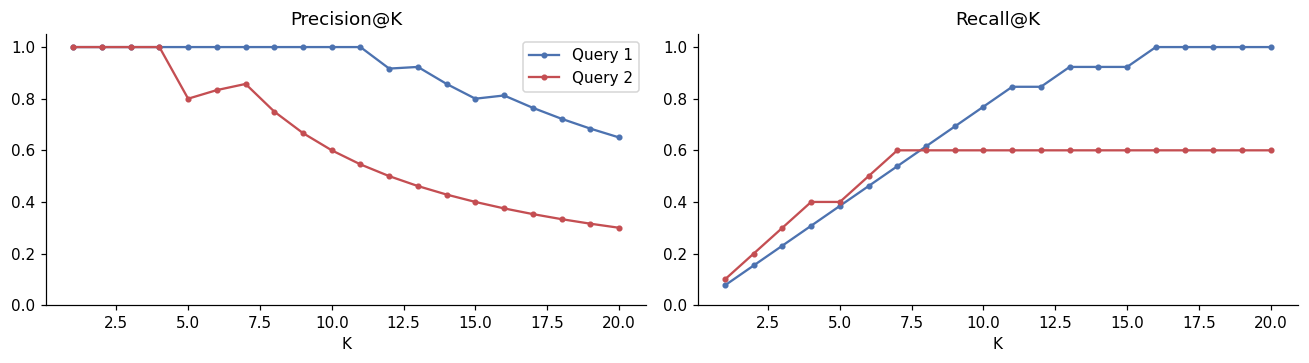

In [15]:
# P@K and R@K for K = 1..20
ks = np.arange(1, 21)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for (qid, (y_true, y_score)), color in zip(val_runs.items(), ["#4C72B0", "#C44E52"]):
    axes[0].plot(ks, [precision_at_k(y_true, y_score, k) for k in ks], marker="o", ms=3, color=color, label=f"Query {qid}")
    axes[1].plot(ks, [recall_at_k(y_true, y_score, k) for k in ks], marker="o", ms=3, color=color, label=f"Query {qid}")
axes[0].set(title="Precision@K", xlabel="K", ylim=(0, 1.05))
axes[1].set(title="Recall@K", xlabel="K", ylim=(0, 1.05))
axes[0].legend()
savefig("validation_precision_recall_at_k")
plt.show()

## 7. Evaluation on our test queries

We acted as expert judges: for each of our five queries we labelled the top-20 products returned
by the system as relevant (1) or not (0), see `test_queries_to_label.csv`.

* `y_score = 1 / rank`, so the metrics follow the order in which the products were returned.
* Only the top-20 were judged (pooling), so *R* = relevant products **within the judged pool**.
  Recall is therefore an upper bound: relevant products below rank 20 are not counted.

In [16]:
test_labels.groupby(["query_id", "query"]).label.agg(judged="size", relevant="sum")

,,judged,relevant
query_id,query,,
1,men cotton polo tshirt,20,19
2,women cotton kurta,20,20
3,men hooded sweatshirt,20,20
4,men running shoes,20,11
5,women blue denim jacket,20,13


In [17]:
test_runs = {qid: (g.label.to_numpy(), 1 / g["rank"].to_numpy())
             for qid, g in test_labels.sort_values("rank").groupby("query_id")}
test_table = metrics_table(test_runs)
test_table

,P@5,R@5,F1@5,AP@5,RR@5,NDCG@5,P@10,R@10,F1@10,AP@10,RR@10,NDCG@10,P@20,R@20,F1@20,AP@20,RR@20,NDCG@20
query_id,,,,,,,,,,,,,,,,,,
1,1.00,0.263,0.417,1.00,1.0,1.000,1.00,0.526,0.690,1.000,1.0,1.000,0.95,1.0,0.974,1.000,1.0,1.000
2,1.00,0.250,0.400,1.00,1.0,1.000,1.00,0.500,0.667,1.000,1.0,1.000,1.00,1.0,1.000,1.000,1.0,1.000
3,1.00,0.250,0.400,1.00,1.0,1.000,1.00,0.500,0.667,1.000,1.0,1.000,1.00,1.0,1.000,1.000,1.0,1.000
4,0.80,0.364,0.500,0.95,1.0,0.854,0.90,0.818,0.857,0.906,1.0,0.905,0.55,1.0,0.710,0.907,1.0,0.967
5,1.00,0.385,0.556,1.00,1.0,1.000,1.00,0.769,0.870,1.000,1.0,1.000,0.65,1.0,0.788,1.000,1.0,1.000
mean,0.96,0.302,0.454,0.99,1.0,0.971,0.98,0.623,0.750,0.981,1.0,0.981,0.83,1.0,0.894,0.981,1.0,0.993


In [18]:
# Reproducibility: the current engine should return the same top-20 that we labelled.
for qid, q in TEST_QUERIES.items():
    labelled = test_labels[test_labels.query_id == qid].sort_values("rank").pid.tolist()
    current = search(q, top_k=20).pid.tolist()
    print(f"Query {qid} ({q}): {len(set(labelled) & set(current))}/20 in common, same order: {labelled == current}")

Query 1 (men cotton polo tshirt): 20/20 in common, same order: True
Query 2 (women cotton kurta): 20/20 in common, same order: True
Query 3 (men hooded sweatshirt): 20/20 in common, same order: True
Query 4 (men running shoes): 20/20 in common, same order: True
Query 5 (women blue denim jacket): 20/20 in common, same order: True


## 8. Save the results

The metric tables are saved as CSV for the report.

In [19]:
val_table.to_csv(PART2 / "results_validation.csv")
test_table.to_csv(PART2 / "results_test_queries.csv")
print("Saved results_validation.csv and results_test_queries.csv in", PART2.relative_to(ROOT))

Saved results_validation.csv and results_test_queries.csv in project_progress/part_2


## Summary

| Step | Decision |
|---|---|
| Index | inverted index on `all_tokens`; tf normalised by document vector length; idf = log(N/df) |
| Retrieval | conjunctive (AND), intersection of the postings lists |
| Queries | same `preprocess_text` pipeline as documents |
| Ranking | TF-IDF dot product; ties broken by pid |
| Metrics | P@K, R@K, F1@K, AP@K, MAP@K, MRR@K, NDCG@K at K = 5, 10, 20 |
| Validation queries | judged products not returned by the AND search get score 0 (not retrieved) |
| Our test queries | top-20 judged by us, scored by 1/rank; recall relative to the judged pool |